# Лабораторная 1. Языковая модель из счётчиков

Дина Ермилова, МТИ2531. Собираем биграммы на «Войне и мире», генерируем текст и проверяем модель на последних 10% слов. Нейросети и BPE здесь не запускаются. Код модели находится в `pt01/run.py`, расчёты этой работы в `lab01/run.py`.

Для повторения откройте ноутбук в клоне репозитория, установите `lab01/requirements.txt` и выполните все ячейки. Если книги нет, скрипт скачает её по указанной ниже открытой ссылке. Готовые результаты не подставляются: ячейка расчёта создаёт их заново.

## 1. Подключаем код и фиксируем источник

In [1]:
from pathlib import Path
import sys, json, math, os, tempfile
root = Path.cwd().resolve()
if root.name == "lab01":
    root = root.parent
assert (root / "pt01/run.py").is_file(), "Откройте ноутбук из корня клона или папки lab01"
sys.path.insert(0, str(root))
from lab01.run import build_results, save_results
from pt01.run import BigramModel, CORPUS_URL
print("Источник:", CORPUS_URL)
print("Seed: 42. Обучение: первые 90% слов. Проверка: последние 10%.")

Источник: https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt
Seed: 42. Обучение: первые 90% слов. Проверка: последние 10%.


## 2. Как счётчики становятся вероятностями

Для каждого предыдущего слова считаем его продолжения. Со сглаживанием вероятность равна `(число пары + alpha) / (число продолжений предыдущего слова + alpha * размер словаря)`. Последнее слово обучающей последовательности не имеет продолжения и не увеличивает знаменатель. Незнакомые слова отображаются в `<UNK>`. Посмотрим это на трёх наблюдавшихся переходах.

In [2]:
toy = BigramModel(alpha=0.01).fit(["кот", "ест", "кот", "спит"])
print("Пары:", dict(toy.pair_counts))
print("P(ест | кот) =", toy.prob("кот", "ест"))
print("P(спит | кот) =", toy.prob("кот", "спит"))
print("P(незнакомое | кот) =", toy.prob("кот", "неизвестное"))
assert math.isclose(sum(toy.prob("кот", w) for w in toy.vocab), 1.0)

Пары: {('кот', 'ест'): 1, ('ест', 'кот'): 1, ('кот', 'спит'): 1}
P(ест | кот) = 0.4950980392156863
P(спит | кот) = 0.4950980392156863
P(незнакомое | кот) = 0.004901960784313725


## 3. Считаем модель на книге

Слова выделяем выражением `[а-я]+(?:-[а-я]+)*`: переводим текст в нижний регистр, заменяем «ё» на «е». Пунктуацию отбрасываем, чтобы моделировать переходы между словами; границы предложений модель поэтому не различает. Статистика всей книги описательная, а пары и словарь модели считаются только по обучающим 90%.

In [3]:
results = build_results()
path = save_results(results, root / "lab01/artifacts")
print("Слов всего:", results["words"])
print("Разных слов во всей книге:", results["vocab_size"])
print("Обучающих слов:", results["train_words"])
print("Проверочных слов:", results["val_words"])
print("Словарь модели с <UNK>:", results["train_vocab_size_with_unk"])
print("SHA256 книги:", results["corpus_sha256"])
print("20 самых частых слов:")
for word, count in results["top20"]:
    print(f"{word:12s} {count:6d}")

Слов всего: 433082
Разных слов во всей книге: 48117
Обучающих слов: 389773
Проверочных слов: 43309
Словарь модели с <UNK>: 45310
SHA256 книги: 147c3ac16b2eb924b0c29995a3afd2c156a363d9be172faff8e6bf7e3ecc4af7
20 самых частых слов:
и             21085
в             10870
не             8520
что            7600
он             7395
на             6665
с              5861
как            4011
его            3895
к              3428
я              2854
она            2732
но             2725
все            2674
было           2501
это            2434
то             2261
сказал         2000
так            1954
о              1832


## 4. Пять разных начал
Для каждого начала выбираем следующие слова по распределению модели, всего 30 слов при температуре 1.0 и alpha=0.01. Seed одинаковый, начальный контекст разный.

In [4]:
for row in results["generation"]:
    assert len(row["text"].split()) == 30
    print(row["start"].upper() + ":")
    print(row["text"] + "\n")
assert len({r["start"] for r in results["generation"]}) == 5

КНЯЗЬ:
князь дрожащим беспечностью излить заводя рамами принимаясь тревоги возвышал нашествии бешеным жизненности осторожными бесполезное дружны презрительного переговорим заброшенным подскакивал слышалась анисьюшка смелости пронзительно-жестким кутузовские гримасой хозяйства курские воображаем воспитатель старшин

ОНА:
она подошла беспокойно имена завистью разумевшееся принимаясь тревоги возвышал нашествии бешеным жизненности осторожными бесполезное дружны презрительного переговорим заброшенным подскакивал слышалась анисьюшка смелости пронзительно-жестким кутузовские гримасой хозяйства курские воображаем воспитатель старшин

ПЬЕР:
пьер понял берейтор ильинишна заводя рамами принимаясь тревоги возвышал нашествии бешеным жизненности осторожными бесполезное дружны презрительного переговорим заброшенным подскакивал слышалась анисьюшка смелости пронзительно-жестким кутузовские гримасой хозяйства курские воображаем воспитатель старшин

НАТАША:
наташа полотенцах берущего изнанкой завистью ра

## 5. Меняем температуру
Возводим вероятности в степень `1/T` и делим на их сумму. Ниже один старт и один seed: меняется только температура.

In [5]:
for row in results["temperature_generation"]:
    print(f"T={row['temperature']}:")
    print(row["text"] + "\n")

T=0.5:
князь андрей был в котором он не только в отношении административном комочком наблюдала благороднее заперлась поверенного нерассчитанного братец ты не будет сказал он как будто спрашивая не было быть так

T=1.0:
князь дрожащим беспечностью излить заводя рамами принимаясь тревоги возвышал нашествии бешеным жизненности осторожными бесполезное дружны презрительного переговорим заброшенным подскакивал слышалась анисьюшка смелости пронзительно-жестким кутузовские гримасой хозяйства курские воображаем воспитатель старшин

T=2.0:
князь посылаю берут изменники завернуто раненную приняли трепака возил небольшую бешенством жуя остановились бесполезным другую предполагалось переворотов заботливо подрагивающею смелость аниска слоном пропадаешь лавра гренадеров хозяйственные куражились воля восклицание стариковского



При T=0.5 вероятные продолжения получают больший перевес, при T=2 распределение становится более равномерным. Это меняет выбор слов, но не добавляет модели память: она по-прежнему видит только одно предыдущее слово.

## 6. Связный и перемешанный текст
Берём первые 12 проверочных слов и фиксированную перестановку тех же слов. Сначала проверяем пары без сглаживания, затем сравниваем суммы логарифмов при alpha=0.01.

In [6]:
lk = results["likelihood"]
for name in ["sentence", "shuffled"]:
    unsmoothed = results["unsmoothed"][name]
    print(name + ":", lk[name])
    print("Не встречалось пар:", unsmoothed["unseen_pairs"])
    print("Без сглаживания:", unsmoothed["logprob"] if unsmoothed["finite"] else "log P = -inf, вероятность равна 0")
    print("Со сглаживанием: log P =", round(lk["logprob_" + name], 4))
assert sorted(lk["sentence"].split()) == sorted(lk["shuffled"].split())
assert lk["logprob_sentence"] > lk["logprob_shuffled"]

sentence: это был георгий й степени на другой день были у фельдмаршала обед
Не встречалось пар: 5
Без сглаживания: log P = -inf, вероятность равна 0
Со сглаживанием: log P = -83.1429
shuffled: день на георгий были у другой обед й степени это был фельдмаршала
Не встречалось пар: 6
Без сглаживания: log P = -inf, вероятность равна 0
Со сглаживанием: log P = -94.8913


Если хотя бы одна пара не встречалась, произведение вероятностей равно нулю, а логарифм равен минус бесконечности. Два таких результата не позволяют сравнить правдоподобие. Лаплас даёт каждой паре положительную вероятность; после сглаживания большее, то есть менее отрицательное значение log P означает более правдоподобный текст.

## 7. Перплексия на всей отложенной части
Складываем логарифмы вероятностей настоящих следующих слов, меняем знак, делим на число переходов и берём экспоненту. Первое слово служит контекстом, поэтому оценивается на один переход меньше, чем слов.

Оцененных переходов: 43308
alpha=1.0: perplexity=15748.1131
alpha=0.1: perplexity=7743.5441
alpha=0.01: perplexity=5309.6357


Matplotlib is building the font cache; this may take a moment.


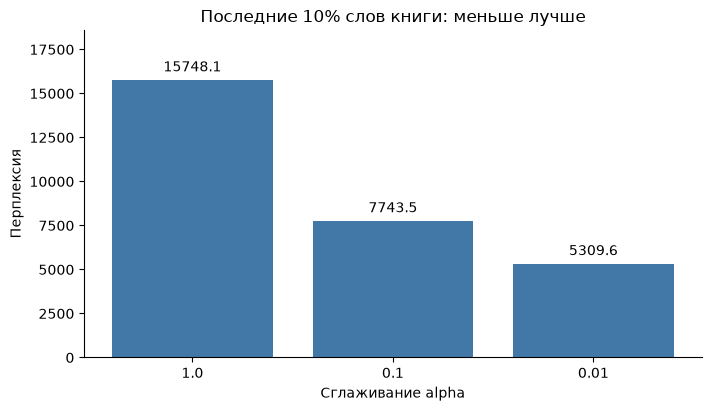

In [7]:
print("Оцененных переходов:", results["prediction_count"])
for alpha, value in results["perplexity"].items():
    print(f"alpha={alpha}: perplexity={value:.4f}")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "lab01-matplotlib"))
import matplotlib.pyplot as plt
values = list(results["perplexity"].values())
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(list(results["perplexity"]), values, color="#4178a8")
ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=4)
ax.set(xlabel="Сглаживание alpha", ylabel="Перплексия", title="Последние 10% слов книги: меньше лучше", ylim=(0, max(values)*1.18))
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(root / "lab01/artifacts/perplexity.png", dpi=140)
plt.show()
plt.close(fig)

## 8. Проверки и выводы

Сопоставим пересчитанные метрики с исходной работой pt01: текст и способ оценки те же, поэтому результаты должны совпасть. Дополнительные начала генерации на перплексию не влияют.

In [8]:
reference = json.loads((root / "pt01/artifacts/bigram.json").read_text())
for alpha, value in results["perplexity"].items():
    assert math.isclose(value, reference["perplexity"][str(float(alpha)).removesuffix(".0")], rel_tol=1e-12)
assert results["train_words"] + results["val_words"] == results["words"]
assert all(math.isfinite(p) and p > 1 for p in values)
print("Проверки пройдены. Результаты:", path.relative_to(root))
best = min(results["perplexity"], key=results["perplexity"].get)
print("Наименьшая перплексия при alpha =", best)

Проверки пройдены. Результаты: lab01/artifacts/bigram.json
Наименьшая перплексия при alpha = 0.01


При слишком большом alpha значительная часть вероятности уходит ненаблюдавшимся продолжениям, поэтому реальные сочетания получают меньшую вероятность. Биграмма воспроизводит отдельные частые сочетания, но не сохраняет тему и дальние грамматические связи. Снижение температуры делает выбор предсказуемее, однако не устраняет это ограничение. Для длинного контекста в следующей работе используется трансформер.